In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load cleaned dataset
df = pd.read_csv("Artworks_dates_analysis (1).csv")

# Use year_mid as the numerical creation-year variable
years = df["year_mid"].dropna()

print("Number of usable records:", len(years))
print("Population mean:", years.mean())
print("Population standard deviation:", years.std(ddof=0))


Number of usable records: 155118
Population mean: 1956.7111392617232
Population standard deviation: 34.048648496423944


In [2]:
# Population parameters
population_mean = years.mean()
population_std = years.std(ddof=0)

print(f"Population mean: {population_mean:.3f}")
print(f"Population SD: {population_std:.3f}")

Population mean: 1956.711
Population SD: 34.049


In [3]:
# Set random seed so the result is reproducible
np.random.seed(42)

# Draw one random sample
sample_3000 = years.sample(
    n=3000,
    replace=False,
    random_state=42
)

# Calculate sample statistics
sample_mean = sample_3000.mean()
sample_std = sample_3000.std(ddof=1)

# Absolute error compared with population mean
absolute_error = abs(sample_mean - population_mean)

print(f"Sample size: {len(sample_3000)}")
print(f"Sample mean: {sample_mean:.3f}")
print(f"Sample SD: {sample_std:.3f}")
print(f"Population mean: {population_mean:.3f}")
print(f"Absolute error: {absolute_error:.3f}")

Sample size: 3000
Sample mean: 1956.389
Sample SD: 33.556
Population mean: 1956.711
Absolute error: 0.322


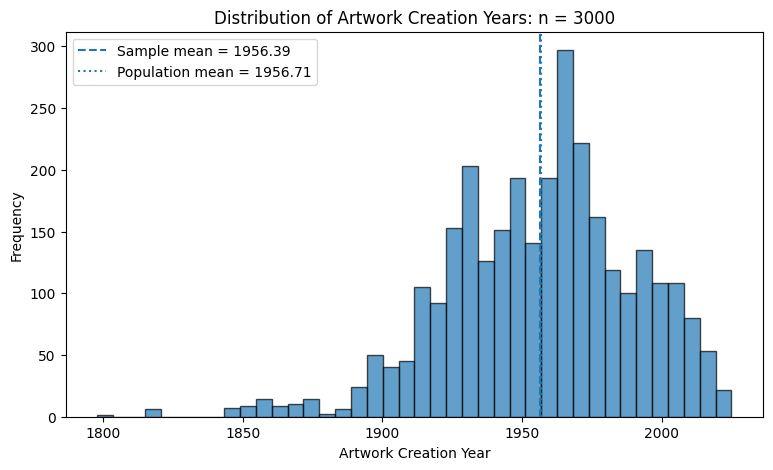

In [4]:
plt.figure(figsize=(9, 5))

plt.hist(
    sample_3000,
    bins=40,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    sample_mean,
    linestyle="--",
    label=f"Sample mean = {sample_mean:.2f}"
)

plt.axvline(
    population_mean,
    linestyle=":",
    label=f"Population mean = {population_mean:.2f}"
)

plt.xlabel("Artwork Creation Year")
plt.ylabel("Frequency")
plt.title("Distribution of Artwork Creation Years: n = 3000")
plt.legend()

plt.show()

In [5]:
# Sampling settings
sample_size = 3000
n_repetitions = 500

# Store the sample mean from each repetition
sample_means_3000 = []

for i in range(n_repetitions):

    sample = years.sample(
        n=sample_size,
        replace=False,
        random_state=i
    )

    sample_means_3000.append(sample.mean())

sample_means_3000 = np.array(sample_means_3000)

In [6]:
mean_of_sample_means = sample_means_3000.mean()

sd_of_sample_means = sample_means_3000.std(ddof=1)

mean_absolute_error = np.mean(
    np.abs(sample_means_3000 - population_mean)
)

theoretical_se = population_std / np.sqrt(sample_size)

print(f"Population mean: {population_mean:.3f}")

print(
    f"Mean of 500 sample means: "
    f"{mean_of_sample_means:.3f}"
)

print(
    f"SD of sample means: "
    f"{sd_of_sample_means:.3f}"
)

print(
    f"Theoretical standard error: "
    f"{theoretical_se:.3f}"
)

print(
    f"Mean absolute error: "
    f"{mean_absolute_error:.3f}"
)

Population mean: 1956.711
Mean of 500 sample means: 1956.715
SD of sample means: 0.591
Theoretical standard error: 0.622
Mean absolute error: 0.477


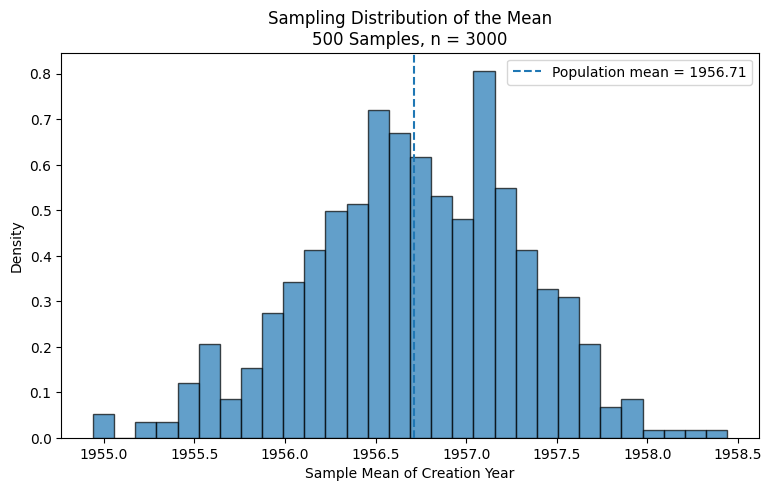

In [7]:
plt.figure(figsize=(9, 5))

plt.hist(
    sample_means_3000,
    bins=30,
    density=True,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    population_mean,
    linestyle="--",
    label=f"Population mean = {population_mean:.2f}"
)

plt.xlabel("Sample Mean of Creation Year")
plt.ylabel("Density")

plt.title(
    "Sampling Distribution of the Mean\n"
    "500 Samples, n = 3000"
)

plt.legend()

plt.show()

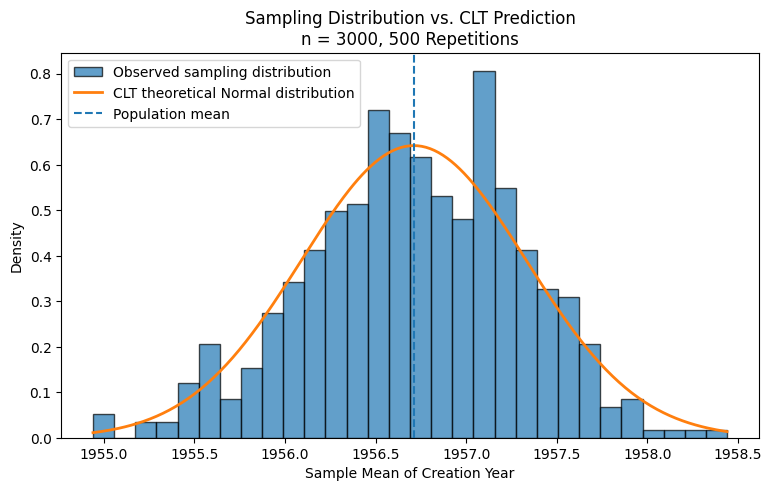

In [8]:
# Create x-values around the observed sample means
x = np.linspace(
    sample_means_3000.min(),
    sample_means_3000.max(),
    300
)

# Normal density function
normal_density = (
    1 / (theoretical_se * np.sqrt(2 * np.pi))
    * np.exp(
        -0.5
        * ((x - population_mean) / theoretical_se) ** 2
    )
)

plt.figure(figsize=(9, 5))

plt.hist(
    sample_means_3000,
    bins=30,
    density=True,
    edgecolor="black",
    alpha=0.7,
    label="Observed sampling distribution"
)

plt.plot(
    x,
    normal_density,
    linewidth=2,
    label="CLT theoretical Normal distribution"
)

plt.axvline(
    population_mean,
    linestyle="--",
    label="Population mean"
)

plt.xlabel("Sample Mean of Creation Year")
plt.ylabel("Density")

plt.title(
    "Sampling Distribution vs. CLT Prediction\n"
    "n = 3000, 500 Repetitions"
)

plt.legend()

plt.show()